<a href="https://colab.research.google.com/github/Veniveni123/CSA47-DEEP-LEARNING/blob/main/LAB-2/Experiment%2013%3A%20Sequential%20Dataset%20Preparation%20and%20RNN%20Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


MAE: 16.88 MW | RMSE: 21.74 MW


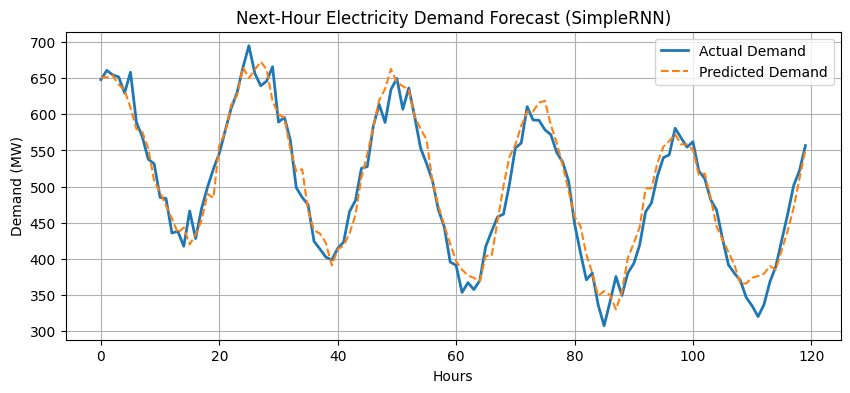

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error
import tensorflow as tf
from tensorflow import keras

np.random.seed(42)
tf.random.set_seed(42)

t = np.arange(1500)
demand = 500 + 120 * np.sin(2 * np.pi * t / 24) + 50 * np.sin(2 * np.pi * t / 168) + np.random.normal(0, 15, len(t))
df = pd.DataFrame({'Demand': demand})
df.loc[10:15, 'Demand'] = np.nan
df['Demand'] = df['Demand'].interpolate()

scaler = MinMaxScaler()
scaled = scaler.fit_transform(df[['Demand']])

win = 24
X, y = [], []
for i in range(len(scaled) - win):
    X.append(scaled[i:i+win])
    y.append(scaled[i+win])
X, y = np.array(X), np.array(y)

split = int(0.8 * len(X))
X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]

model = keras.Sequential([
    keras.layers.SimpleRNN(32, activation='tanh', input_shape=(win, 1)),
    keras.layers.Dense(1)
])
model.compile(optimizer='adam', loss='mse')
model.fit(X_train, y_train, epochs=12, batch_size=32, verbose=0)

preds = scaler.inverse_transform(model.predict(X_test, verbose=0))
actual = scaler.inverse_transform(y_test)

mae = mean_absolute_error(actual, preds)
rmse = np.sqrt(mean_squared_error(actual, preds))
print(f"MAE: {mae:.2f} MW | RMSE: {rmse:.2f} MW")

plt.figure(figsize=(10, 4))
plt.plot(actual[:120], label='Actual Demand', linewidth=2)
plt.plot(preds[:120], label='Predicted Demand', linestyle='--')
plt.title("Next-Hour Electricity Demand Forecast (SimpleRNN)")
plt.xlabel("Hours")
plt.ylabel("Demand (MW)")
plt.legend()
plt.grid(True)
plt.show()